[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/option-pricing-python/blob/main/03_greeks.ipynb)

# 3. The Greeks

Sensitivities of the option price:

| Greek | Sensitivity to |
|---|---|
| Delta | spot price |
| Gamma | spot price, second order (how fast delta changes) |
| Vega | volatility (per 1 vol point) |
| Theta | time (per day) |
| Rho | interest rate (per 1% move) |

The closed-form formulas are checked against a numerical estimate (bump the input a little and
reprice).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def bs_price(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [3]:
def greeks(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(T))
    vega = S * norm.pdf(d1) * np.sqrt(T) / 100
    if kind == "call":
        delta = norm.cdf(d1)
        theta = (-S * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2)) / 365
        rho = K * T * np.exp(-r * T) * norm.cdf(d2) / 100
    else:
        delta = norm.cdf(d1) - 1
        theta = (-S * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) + r * K * np.exp(-r * T) * norm.cdf(-d2)) / 365
        rho = -K * T * np.exp(-r * T) * norm.cdf(-d2) / 100
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}

In [4]:
S, K, T, r, sigma = 100, 100, 1.0, 0.03, 0.20
h = 1e-4
price = lambda S=S, T=T, r=r, sigma=sigma: bs_price(S, K, T, r, sigma, "call")

numerical = {
    "delta": (price(S=S + h) - price(S=S - h)) / (2 * h),
    "gamma": (price(S=S + h) - 2 * price() + price(S=S - h)) / h**2,
    "vega": (price(sigma=sigma + h) - price(sigma=sigma - h)) / (2 * h) / 100,
    "theta": -(price(T=T + h) - price(T=T - h)) / (2 * h) / 365,
    "rho": (price(r=r + h) - price(r=r - h)) / (2 * h) / 100,
}
formula = greeks(S, K, T, r, sigma, "call")

print("greek     formula     numerical")
for g in formula:
    print(f"{g:6s} {formula[g]:10.5f} {numerical[g]:12.5f}")
    assert abs(formula[g] - numerical[g]) < 1e-3

greek     formula     numerical
delta     0.59871      0.59871
gamma     0.01933      0.01933
vega      0.38667      0.38667
theta    -0.01474     -0.01474
rho       0.50457      0.50457


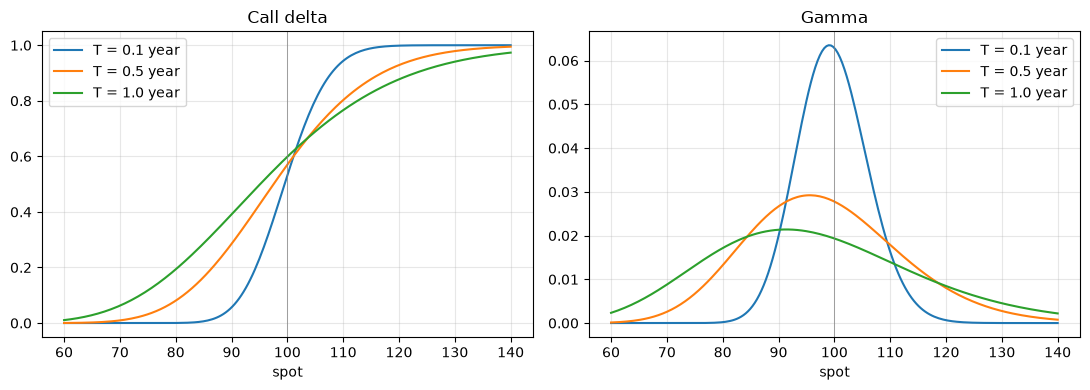

In [5]:
spots = np.linspace(60, 140, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for T_ in [0.1, 0.5, 1.0]:
    g = greeks(spots, K, T_, r, sigma, "call")
    axes[0].plot(spots, g["delta"], label=f"T = {T_} year")
    axes[1].plot(spots, g["gamma"], label=f"T = {T_} year")
axes[0].set_title("Call delta"); axes[1].set_title("Gamma")
for ax in axes:
    ax.set_xlabel("spot"); ax.axvline(K, color="grey", lw=0.5); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Delta goes from 0 to 1 as the call moves into the money; close to expiry it becomes a step.
- Gamma is highest at the money and close to expiry: that is where the hedge has to be adjusted
  the most.